# **1. Train Period: 데이터 수집 및 전처리 (Data)**

In [ ]:
import pandas as pd
import yfinance as yf

# 1. 대상 종목 및 yfinance 티커(Ticker) 매핑 (코스피 50개 종목)
ticker_dict = {
    "삼성전자": "005930.KS",
    "SK하이닉스": "000660.KS",
    "삼성전자우": "005935.KS",
    "SK스퀘어": "402340.KS",
    "현대차": "005380.KS",
    "삼성전기": "009150.KS",
    "LG에너지솔루션": "373220.KS",
    "삼성생명": "032830.KS",
    "삼성물산": "028260.KS",
    "HD현대중공업": "329180.KS",
    "기아": "000270.KS",
    "삼성바이오로직스": "207940.KS",
    "KB금융": "105560.KS",
    "현대모비스": "012330.KS",
    "두산에너빌리티": "034020.KS",
    "한화에어로스페이스": "012450.KS",
    "신한지주": "055550.KS",
    "NAVER": "035420.KS",
    "LG전자": "066570.KS",
    "SK": "034730.KS",
    "삼성SDI": "006400.KS",
    "셀트리온": "068270.KS",
    "HD현대일렉트릭": "267260.KS",
    "한화오션": "042660.KS",
    "LS ELECTRIC": "010120.KS",
    "하나금융지주": "086790.KS",
    "삼성화재": "000810.KS",
    "효성중공업": "298040.KS",
    "POSCO홀딩스": "005490.KS",
    "미래에셋증권": "006800.KS",
    "KODEX 200": "069500.KS",
    "LG이노텍": "011070.KS",
    "두산": "000150.KS",
    "HD한국조선해양": "009540.KS",
    "한미반도체": "042700.KS",
    "고려아연": "010130.KS",
    "한국전력": "015760.KS",
    "삼성중공업": "010140.KS",
    "SK텔레콤": "017670.KS",
    "LG화학": "051910.KS",
    "우리금융지주": "316140.KS",
    "현대오토에버": "307950.KS",
    "HD현대": "267250.KS",
    "현대로템": "064350.KS",
    "TIGER 미국S&P500": "360750.KS",
    "KT&G": "033780.KS",
    "삼성SDS": "018260.KS",
    "SK이노베이션": "096770.KS",
    "HMM": "011200.KS",
    "LG": "003550.KS",
}

tickers = list(ticker_dict.values())

# 2. 데이터 다운로드 기간 설정
start_date = "2010-01-01"
end_date = "2026-05-24"

print("데이터 다운로드를 시작합니다...")

# 3. auto_adjust=False 설정을 추가하여 'Adj Close' 컬럼을 생성하도록 수정
raw_data = yf.download(
    tickers, start=start_date, end=end_date, group_by="column", threads=True, auto_adjust=False
)

print("\n데이터 다운로드 완료!")

# 4. 수정주가(Adj Close) 컬럼만 추출
adj_close_data = raw_data["Adj Close"]

# 5. 컬럼명을 '티커'에서 '종목명'으로 변경
inv_ticker_dict = {v: k for k, v in ticker_dict.items()}
adj_close_data = adj_close_data.rename(columns=inv_ticker_dict)
adj_close_data.index.name = "Date"

# 6. 결측치(NaN) 확인 및 출력
print("\n=== 종목별 결측치(NaN) 개수 확인 ===")
nan_counts = adj_close_data.isna().sum()
print(nan_counts[nan_counts > 0])
if nan_counts.sum() == 0:
    print("결측치가 없습니다.")
else:
    print(f"\n※ 주의: 일부 신규 상장 종목은 상장일 이전 데이터가 NaN으로 표시됩니다.")

# 7. 최종 결과를 CSV 파일로 저장
output_filename = "kospi_pairs_data.csv"
adj_close_data.to_csv(output_filename)
print(f"데이터가 성공적으로 '{output_filename}' 파일로 저장되었습니다.")

데이터 다운로드를 시작합니다...


[*********************100%***********************]  50 of 50 completed



데이터 다운로드 완료!

=== 종목별 결측치(NaN) 개수 확인 ===
Ticker
두산                   1
기아                   1
SK하이닉스               1
삼성화재                 1
LG                   1
현대차                  1
POSCO홀딩스             1
삼성전자                 1
삼성전자우                1
삼성SDI                1
미래에셋증권               1
삼성전기                 1
HD한국조선해양             1
LS ELECTRIC          1
고려아연                 1
삼성중공업                1
LG이노텍                1
HMM                  1
현대모비스                1
한화에어로스페이스            1
한국전력                 1
SK텔레콤                1
삼성SDS             1154
삼성물산              1232
삼성생명                90
KT&G                 1
두산에너빌리티              1
SK                   1
NAVER                1
한화오션                 1
한미반도체                1
LG화학                 1
신한지주                 1
현대로템               952
LG전자                 1
셀트리온                 1
KODEX 200           29
하나금융지주               1
SK이노베이션              1
KB금융                 1
삼성바이오로직스          1700
HD현대    

In [ ]:
import pandas as pd

# 1. 인덱스를 Datetime 형식으로 변환 (변수명을 adj_close_data로 수정)
adj_close_data.index = pd.to_datetime(adj_close_data.index)

# 2. 지침에 따른 기간 설정 및 데이터 분할
# Train Period: 2010-01-01 ~ 2018-12-31
train_df = adj_close_data.loc['2010-01-01':'2018-12-31'].copy()

# Validation Period: 2019-01-01 ~ 2021-12-31
val_df = adj_close_data.loc['2019-01-01':'2021-12-31'].copy()

# Test Period: 2022-01-01 ~ 최신 날짜
test_df = adj_close_data.loc['2022-01-01':].copy()

# 3. 분할 결과 검증 및 출력
def verify_split(name, df):
    if not df.empty:
        start_date = df.index.min().strftime('%Y-%m-%d')
        end_date = df.index.max().strftime('%Y-%m-%d')
        rows = len(df)
        print(f"[{name}] 시작: {start_date} | 종료: {end_date} | 행 수: {rows}")
    else:
        print(f"[{name}] 데이터가 존재하지 않습니다.")

print("--- 데이터 분할 검증 결과 ---")
verify_split("Train     ", train_df)
verify_split("Validation", val_df)
verify_split("Test       ", test_df)
print("----------------------------")

--- 데이터 분할 검증 결과 ---
[Train     ] 시작: 2010-01-04 | 종료: 2018-12-28 | 행 수: 2219
[Validation] 시작: 2019-01-02 | 종료: 2021-12-30 | 행 수: 742
[Test       ] 시작: 2022-01-04 | 종료: 2026-05-22 | 행 수: 1070
----------------------------


# **2. Train Period: Pair Selection & Hedge Ratio($\beta$)추정 (Train 기간만 사용)**

pair 선정

---



In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
import itertools
import warnings
from google.colab import files

warnings.filterwarnings('ignore')

# 1. 데이터 준비 (Train 기간: 2010-01-04 ~ 2018-12-28)
df_train = train_df.loc['2010-01-04':'2018-12-28'].dropna(axis=1, how='any')
tickers = df_train.columns
returns = df_train.pct_change().dropna()
norm_df = df_train / df_train.iloc[0]

def calculate_pair_metrics(p1_name, p2_name):
    P1, P2 = df_train[p1_name], df_train[p2_name]

    # ① 수익률 상관계수 (Correlation)
    rho = returns[p1_name].corr(returns[p2_name])

    # ② 공적분 (Cointegration) 테스트
    score, p_val, _ = coint(P1, P2)

    # Hedge Ratio (Beta) 추정
    X = sm.add_constant(P2)
    model = sm.OLS(P1, X).fit()
    beta = model.params.iloc[1]
    intercept = model.params.iloc[0]

    # ③ Half-life 계산
    spread = P1 - beta * P2 - intercept
    delta_spread = spread.diff().dropna()
    lag_spread = sm.add_constant(spread.shift(1).dropna())

    common_idx = delta_spread.index.intersection(lag_spread.index)
    res_hl = sm.OLS(delta_spread.loc[common_idx], lag_spread.loc[common_idx]).fit()
    gamma = res_hl.params.iloc[1]

    if gamma >= 0: return None
    hl = -np.log(2) / gamma

    # ④ 거리 방법 (Distance Method)
    dist = ((norm_df[p1_name] - norm_df[p2_name])**2).sum()

    return {
        'Stock 1': p1_name, 'Stock 2': p2_name,
        'Correlation': rho, 'Coint_pvalue': p_val, 'Half_life': hl,
        'Distance': dist, 'Beta': beta
    }

results = []
pair_combinations = list(itertools.combinations(tickers, 2))
print(f"총 {len(pair_combinations)}개 페어 분석 시작...")

for p1, p2 in pair_combinations:
    res = calculate_pair_metrics(p1, p2)
    if res: results.append(res)

res_df = pd.DataFrame(results)
# 기본 필터링: 공적분 유의수준 0.05 미만 및 반감기 60일 미만
filtered = res_df[(res_df['Coint_pvalue'] < 0.05) & (res_df['Half_life'] < 60)].copy()

# 최종 점수 산정: 공적분 순위 + 거리 순위 (수익률 제외)
filtered['rank_p'] = filtered['Coint_pvalue'].rank()
filtered['rank_dist'] = filtered['Distance'].rank()
filtered['Score'] = filtered['rank_p'] + filtered['rank_dist']

# --- 중복 종목 제거 로직 ---
sorted_candidates = filtered.sort_values('Score')
unique_pairs = []
used_tickers = set()

for _, row in sorted_candidates.iterrows():
    s1, s2 = row['Stock 1'], row['Stock 2']
    if s1 not in used_tickers and s2 not in used_tickers:
        unique_pairs.append(row)
        used_tickers.add(s1)
        used_tickers.add(s2)
    if len(unique_pairs) >= 3: break

top_3_pairs = pd.DataFrame(unique_pairs)

print("\n=== [최종 선정 페어 트레이딩 Top 3 종목 쌍 (공적분 & 거리 기반)] ===")
display_cols = ['Stock 1', 'Stock 2', 'Correlation', 'Coint_pvalue', 'Half_life', 'Distance', 'Score', 'Beta']
display(top_3_pairs[display_cols])

# --- CSV 다운로드 추가 ---
csv_filename = 'top_3_pairs_selection.csv'
top_3_pairs[display_cols].to_csv(csv_filename, index=False, encoding='utf-8-sig')
print(f"\n결과가 '{csv_filename}'으로 저장되었습니다. 다운로드를 시작합니다...")
files.download(csv_filename)

총 595개 페어 분석 시작...

=== [최종 선정 페어 트레이딩 Top 3 종목 쌍 (공적분 & 거리 기반)] ===


,Stock 1,Stock 2,Correlation,Coint_pvalue,Half_life,Distance,Score,Beta
159,LG,KB금융,0.364390,0.000410,34.353889,114.666209,11.0,1.017894
31,두산,하나금융지주,0.264366,0.000192,28.143955,261.027054,21.0,1.899037
380,LS ELECTRIC,LG전자,0.303902,0.002178,46.374170,36.083425,22.0,0.079920



결과가 'top_3_pairs_selection.csv'으로 저장되었습니다. 다운로드를 시작합니다...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 최종 선정된 pair의 normalized price plot

---



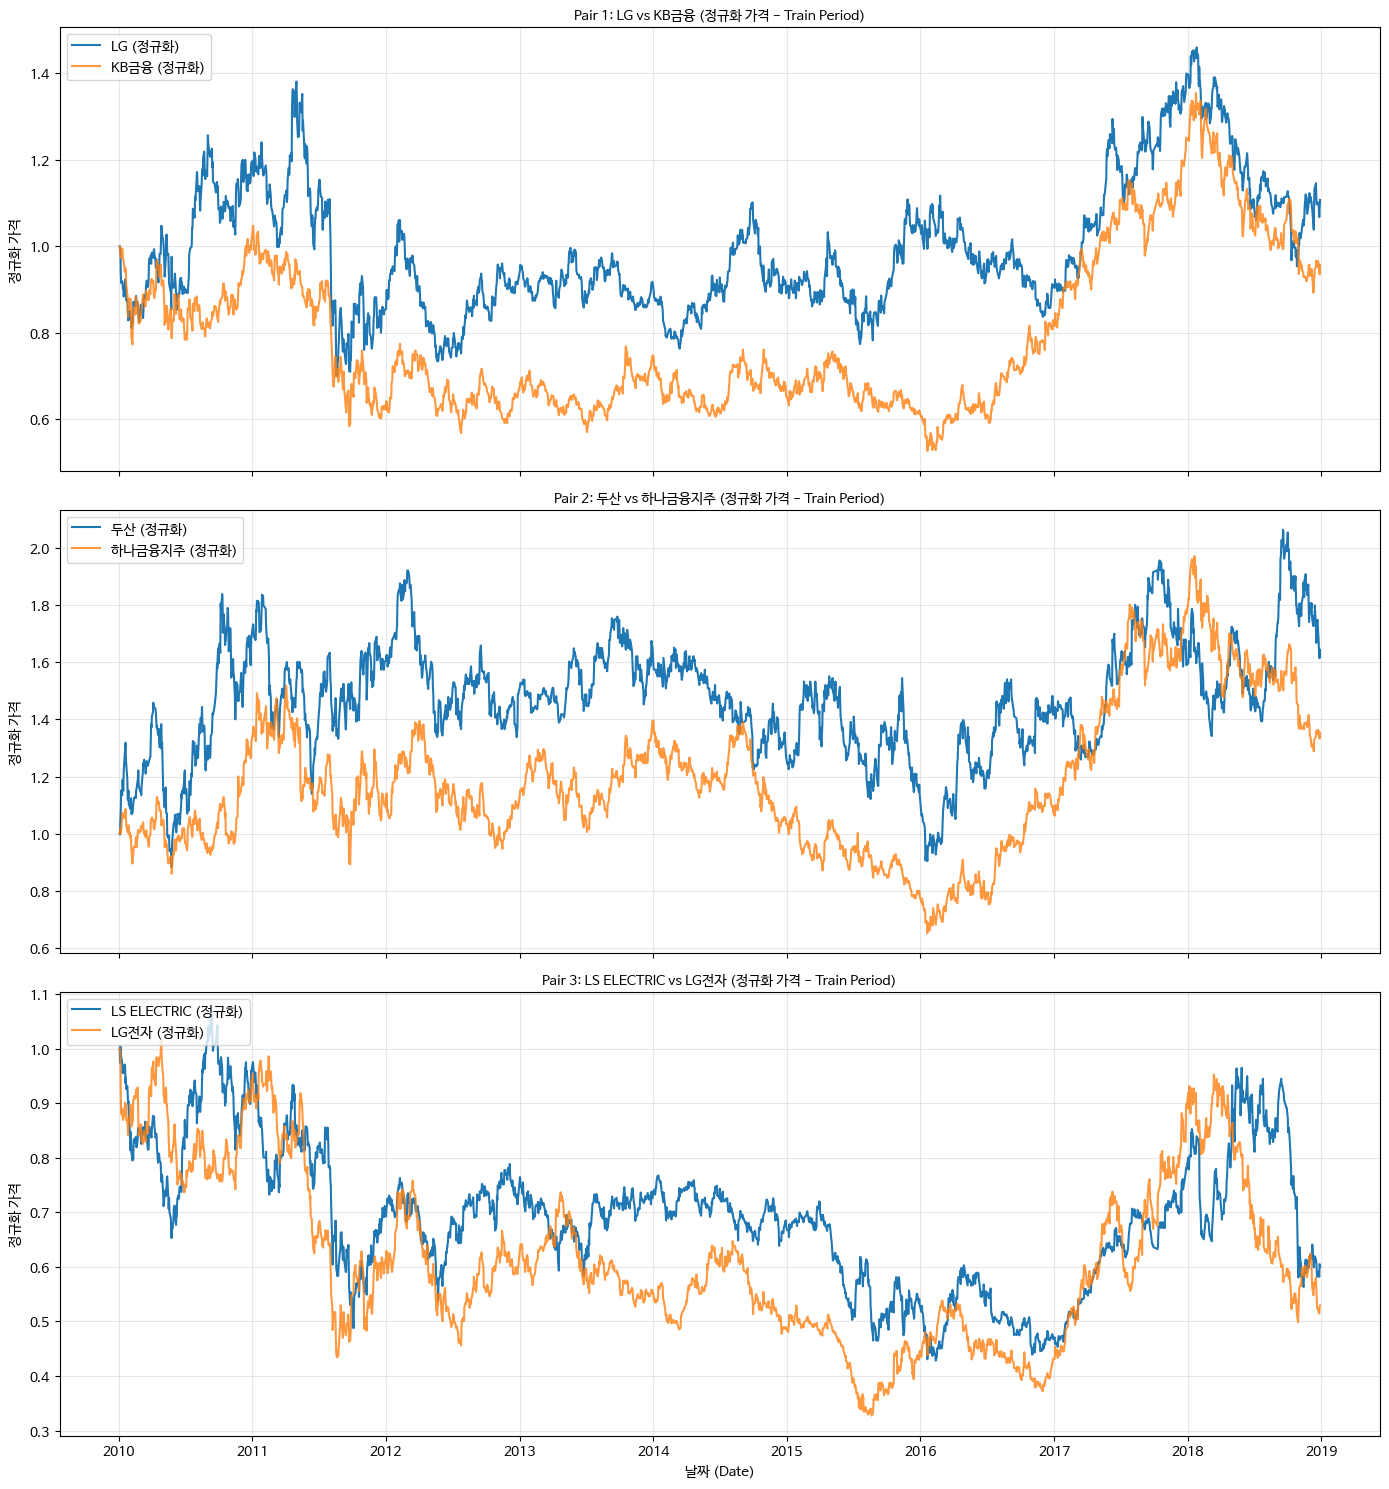

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1. 한글 폰트 설치 및 Matplotlib에 명시적 등록
!apt-get -qq install fonts-nanum

font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
# 폰트 매니저에 폰트 추가
fm.fontManager.addfont(font_path)
# 폰트 속성 설정
font_prop = fm.FontProperties(fname=font_path)
plt.rc('font', family=font_prop.get_name())
plt.rcParams['axes.unicode_minus'] = False

# 2. 시각화 대상 페어 설정 (Top 3)
top_pairs = [
    {'s1': 'LG', 's2': 'KB금융'},
    {'s1': '두산', 's2': '하나금융지주'},
    {'s1': 'LS ELECTRIC', 's2': 'LG전자'}
]

# 3. 서브플롯 생성
fig, axes = plt.subplots(3, 1, figsize=(14, 15), sharex=True)

for i, pair in enumerate(top_pairs):
    s1, s2 = pair['s1'], pair['s2']

    if s1 in df_train.columns and s2 in df_train.columns:
        p1_norm = df_train[s1] / df_train[s1].iloc[0]
        p2_norm = df_train[s2] / df_train[s2].iloc[0]

        axes[i].plot(p1_norm, label=f"{s1} (정규화)", linewidth=1.5)
        axes[i].plot(p2_norm, label=f"{s2} (정규화)", linewidth=1.5, alpha=0.8)

        # 폰트 속성 직접 적용하여 한글 깨짐 방지
        axes[i].set_title(f"Pair {i+1}: {s1} vs {s2} (정규화 가격 - Train Period)",
                          fontsize=14, fontproperties=font_prop)
        axes[i].set_ylabel("정규화 가격", fontproperties=font_prop)
        axes[i].legend(loc='upper left', prop=font_prop)
        axes[i].grid(True, alpha=0.3)

plt.xlabel("날짜 (Date)", fontproperties=font_prop)
plt.tight_layout()
plt.show()

페어별 Spread 및 Z-score 계산

---



In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from google.colab import files

# 1. 데이터 정의 (Train Period 이용)
df_target = train_df.loc['2010-01-04':'2018-12-28'].copy()

# 이전 단계에서 선정된 Top 3 페어 정보 가져오기
pairs_list = []
for _, row in top_3_pairs.iterrows():
    pairs_list.append({'s1': row['Stock 1'], 's2': row['Stock 2']})

results_dict = {}

print("--- 페어별 Spread 및 Z-score 계산 및 다운로드 시작 ---\n")

for pair in pairs_list:
    s1_name, s2_name = pair['s1'], pair['s2']
    P1 = df_target[s1_name]
    P2 = df_target[s2_name]

    # 2. Spread 및 Hedge Ratio (Beta) 계산
    X = sm.add_constant(P2)
    model = sm.OLS(P1, X).fit()
    beta = model.params.iloc[1]
    spread = P1 - (beta * P2)

    # 3. Rolling Window 기반 Z-score 계산 (60일)
    window = 60
    rolling_mean = spread.rolling(window=window).mean()
    rolling_std = spread.rolling(window=window).std()
    z_score = (spread - rolling_mean) / rolling_std

    # 결과 테이블 구성
    res_table = pd.DataFrame({
        'P1 가격': P1,
        'P2 가격': P2,
        'Spread': spread,
        '60일 이동평균': rolling_mean,
        '60일 이동표준편차': rolling_std,
        'Z-score': z_score
    })

    results_dict[f"{s1_name}-{s2_name}"] = res_table

    # CSV 파일 저장 및 다운로드
    file_name = f"pairs_result_{s1_name}_{s2_name}.csv"
    res_table.to_csv(file_name, encoding='utf-8-sig')

    print(f"▶ [Pair: {s1_name} & {s2_name}] (Beta: {beta:.4f})")
    display(res_table.dropna().head(3))

    # 파일 다운로드 실행
    files.download(file_name)
    print(f"{file_name} 다운로드 요청 완료")
    print("-" * 80)

--- 페어별 Spread 및 Z-score 계산 및 다운로드 시작 ---

▶ [Pair: LG & KB금융] (Beta: 1.0179)


,P1 가격,P2 가격,Spread,60일 이동평균,60일 이동표준편차,Z-score
Date,,,,,,
2010-03-30,52874.394531,31823.175781,20481.774925,16353.189839,1747.125285,2.363073
2010-03-31,51851.960938,31998.998047,19280.372902,16364.398493,1763.911834,1.653129
2010-04-01,52947.421875,32174.824219,20196.861435,16387.573539,1805.190681,2.110186


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

pairs_result_LG_KB금융.csv 다운로드 요청 완료
--------------------------------------------------------------------------------
▶ [Pair: 두산 & 하나금융지주] (Beta: 1.8990)


...

pairs_result_두산_하나금융지주.csv 다운로드 요청 완료
--------------------------------------------------------------------------------
▶ [Pair: LS ELECTRIC & LG전자] (Beta: 0.0799)


,P1 가격,P2 가격,Spread,60일 이동평균,60일 이동표준편차,Z-score
Date,,,,,,
2010-03-30,11964.549805,102667.031250,3759.379248,4640.628672,794.025129,-1.109851
2010-03-31,11920.018555,100482.632812,3889.425577,4615.578002,793.612993,-0.914996
2010-04-01,11875.484375,103977.664062,3565.567771,4590.732881,802.862930,-1.276887


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

pairs_result_LS ELECTRIC_LG전자.csv 다운로드 요청 완료
--------------------------------------------------------------------------------


Spread plot

---



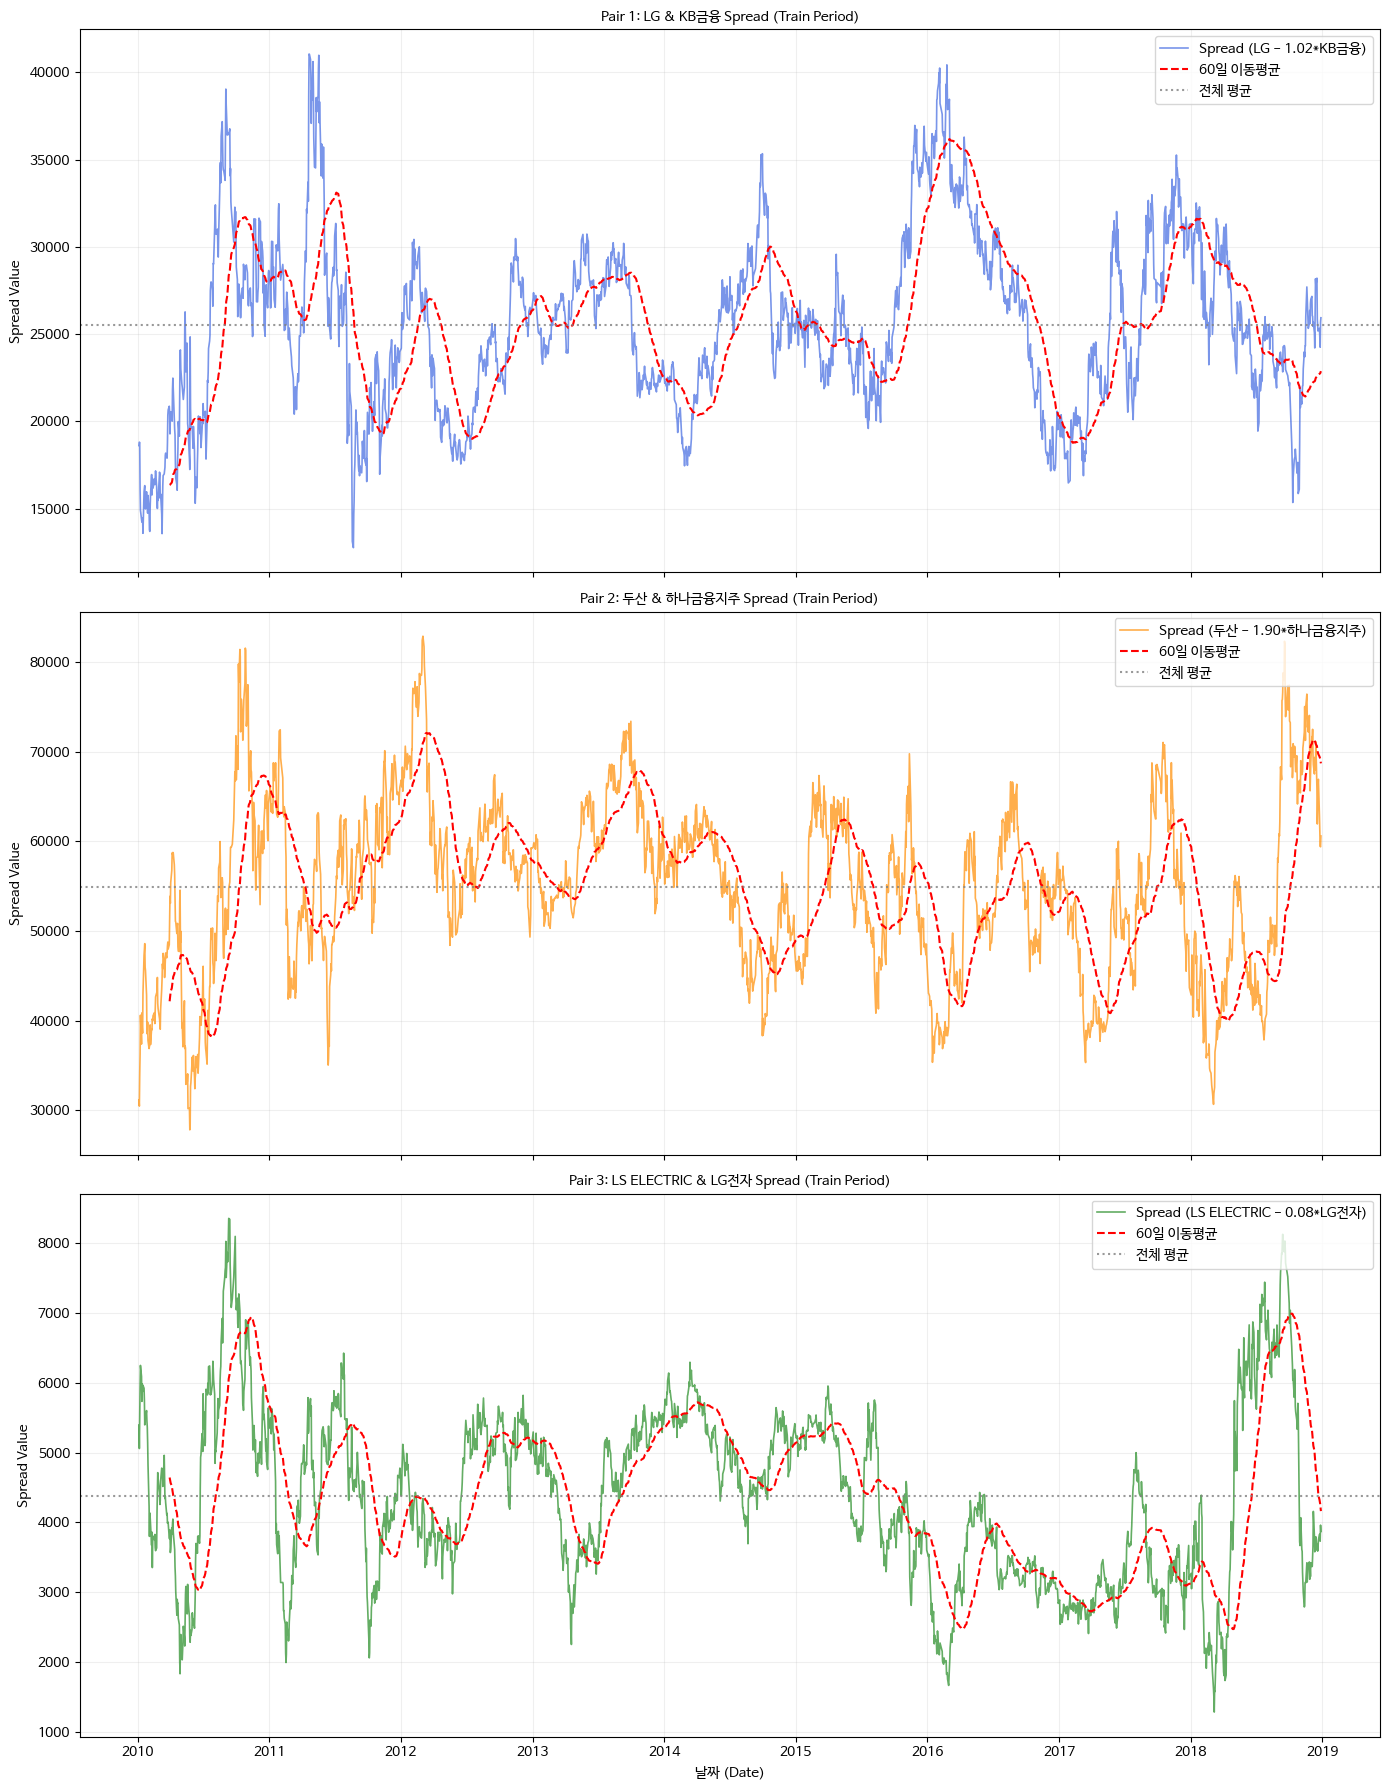

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1. 한글 폰트 설정 (이미 설치된 경로 활용)
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_prop = fm.FontProperties(fname=font_path)

# 2. 분석 대상 페어 정보 및 색상 설정
target_pairs_info = [
    {'s1': 'LG', 's2': 'KB금융', 'beta': 1.0179, 'color': 'royalblue'},
    {'s1': '두산', 's2': '하나금융지주', 'beta': 1.8990, 'color': 'darkorange'},
    {'s1': 'LS ELECTRIC', 's2': 'LG전자', 'beta': 0.0799, 'color': 'forestgreen'}
]
WINDOW = 60

# 3. 시각화 (Spread 플롯 - 색상 변경 버전)
fig, axes = plt.subplots(3, 1, figsize=(14, 18), sharex=True)

for i, pair in enumerate(target_pairs_info):
    s1, s2, beta, color = pair['s1'], pair['s2'], pair['beta'], pair['color']

    # Spread 계산 (df_train 사용)
    spread = df_train[s1] - (beta * df_train[s2])
    roll_mean = spread.rolling(window=WINDOW).mean()

    # 플로팅 (검은색 대신 지정된 색상 사용)
    axes[i].plot(spread, label=f'Spread ({s1} - {beta:.2f}*{s2})', color=color, alpha=0.7, linewidth=1.2)
    axes[i].plot(roll_mean, label=f'{WINDOW}일 이동평균', color='red', linestyle='--', linewidth=1.5)

    # 꾸미기
    axes[i].set_title(f"Pair {i+1}: {s1} & {s2} Spread (Train Period)", fontsize=15, fontproperties=font_prop)
    axes[i].set_ylabel("Spread Value", fontproperties=font_prop)
    axes[i].axhline(spread.mean(), color='gray', linestyle=':', alpha=0.8, label='전체 평균')
    axes[i].legend(loc='upper right', prop=font_prop)
    axes[i].grid(True, alpha=0.2)

plt.xlabel("날짜 (Date)", fontproperties=font_prop)
plt.tight_layout()
plt.show()

 Z-score plot

---



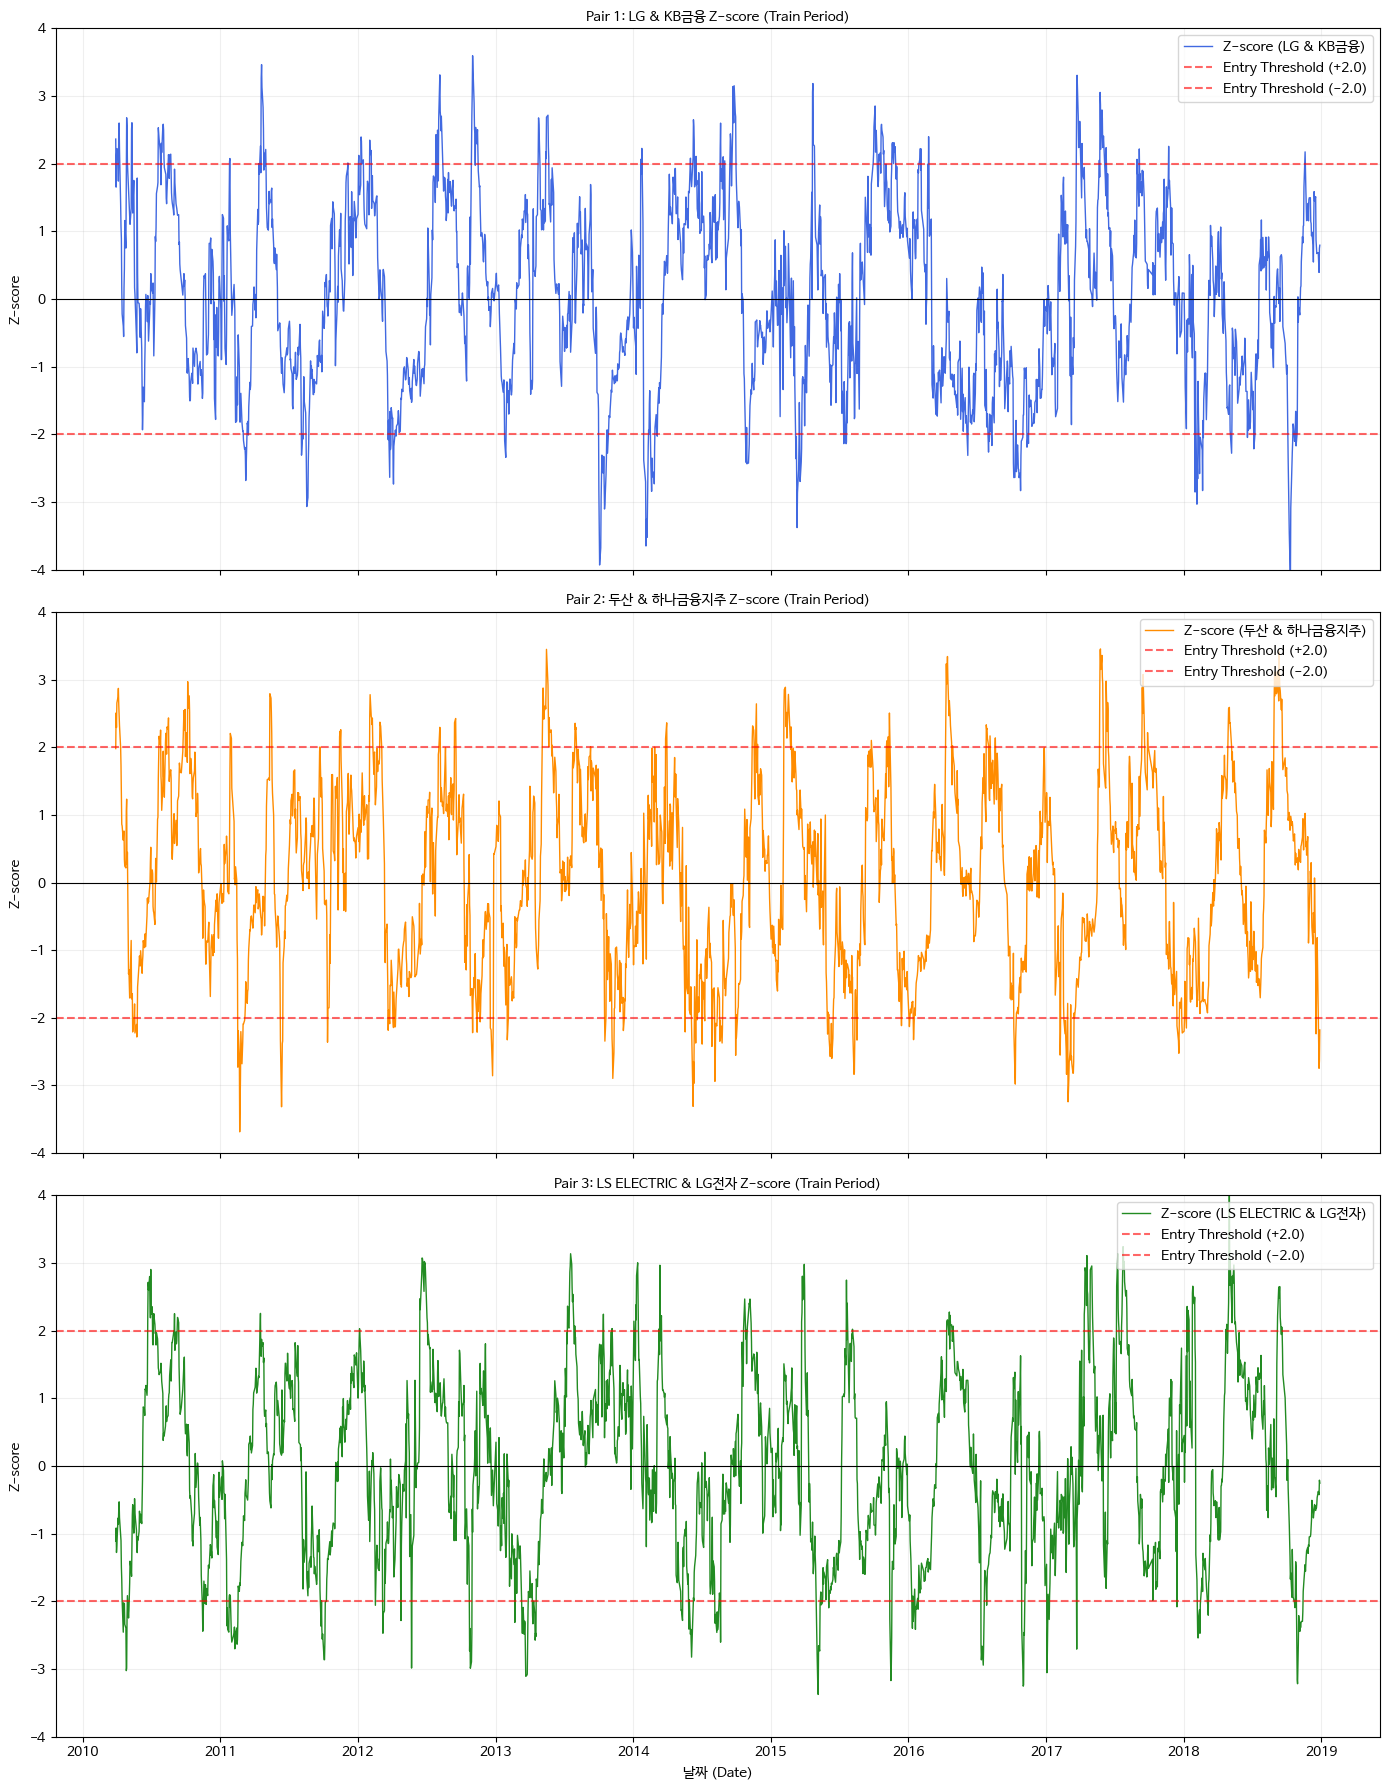

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1. 한글 폰트 및 스타일 설정
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_prop = fm.FontProperties(fname=font_path)
WINDOW = 60

# 2. 페어 정보 (이전 단계에서 확정된 Beta 값 사용)
target_pairs_info = [
    {'s1': 'LG', 's2': 'KB금융', 'beta': 1.0179, 'color': 'royalblue'},
    {'s1': '두산', 's2': '하나금융지주', 'beta': 1.8990, 'color': 'darkorange'},
    {'s1': 'LS ELECTRIC', 's2': 'LG전자', 'beta': 0.0799, 'color': 'forestgreen'}
]

# 3. Z-score 시각화
fig, axes = plt.subplots(3, 1, figsize=(14, 18), sharex=True)

for i, pair in enumerate(target_pairs_info):
    s1, s2, beta, color = pair['s1'], pair['s2'], pair['beta'], pair['color']

    # Spread 계산
    spread = df_train[s1] - (beta * df_train[s2])

    # Z-score 계산 (60일 Rolling)
    rolling_mean = spread.rolling(window=WINDOW).mean()
    rolling_std = spread.rolling(window=WINDOW).std()
    z_score = (spread - rolling_mean) / rolling_std

    # 플로팅
    axes[i].plot(z_score, color=color, label=f'Z-score ({s1} & {s2})', linewidth=1)

    # 임계값 표시 (Entry: ±2.0, Exit: ±1.5 or 0)
    axes[i].axhline(2.0, color='red', linestyle='--', alpha=0.6, label='Entry Threshold (+2.0)')
    axes[i].axhline(-2.0, color='red', linestyle='--', alpha=0.6, label='Entry Threshold (-2.0)')
    axes[i].axhline(0, color='black', linewidth=0.8)

    # 꾸미기
    axes[i].set_title(f"Pair {i+1}: {s1} & {s2} Z-score (Train Period)", fontsize=15, fontproperties=font_prop)
    axes[i].set_ylabel("Z-score", fontproperties=font_prop)
    axes[i].set_ylim(-4, 4) # Z-score 가독성을 위해 범위 제한
    axes[i].legend(loc='upper right', prop=font_prop)
    axes[i].grid(True, alpha=0.2)

plt.xlabel("날짜 (Date)", fontproperties=font_prop)
plt.tight_layout()
plt.show()

# **3. Validation period**

Trading rule 설정

---



In [ ]:
import pandas as pd
import numpy as np

# [수정] test_df가 아닌 val_df를 사용하여 2019-2021 기간만 계산
df_val = val_df.copy()

# Train 단계에서 확정된 페어 및 베타값 고정
target_pairs = [
    {'s1': 'LG', 's2': 'KB금융', 'beta': 1.0179},
    {'s1': '두산', 's2': '하나금융지주', 'beta': 1.8990},
    {'s1': 'LS ELECTRIC', 's2': 'LG전자', 'beta': 0.0799}
]

# 거래 파라미터 설정 (이전 Grid Search를 통해 선정된 최적 파라미터 예시)
WINDOW = 60
ENTRY_K = 2.0
EXIT_K = 0.0
STOP_LOSS = 0.10
MAX_HOLD = 40
COST = 0.0015

def run_validation_test():
    pair_returns_list = []
    closed_trades_pnl = []

    for pair in target_pairs:
        s1, s2, beta = pair['s1'], pair['s2'], pair['beta']

        if s1 not in df_val.columns or s2 not in df_val.columns:
            continue

        spread = df_val[s1] - (beta * df_val[s2])
        roll_mean = spread.rolling(window=WINDOW).mean()
        roll_std = spread.rolling(window=WINDOW).std()
        zscore = (spread - roll_mean) / roll_std

        position = 0
        entry_idx = 0
        entry_spread_val = 0
        daily_returns = pd.Series(0.0, index=df_val.index)

        for t in range(WINDOW, len(df_val)):
            curr_z = zscore.iloc[t]
            curr_spread = spread.iloc[t]

            if position == 0:
                if curr_z > ENTRY_K:
                    position = -1; entry_idx = t; entry_spread_val = curr_spread
                    daily_returns.iloc[t] -= COST
                elif curr_z < -ENTRY_K:
                    position = 1; entry_idx = t; entry_spread_val = curr_spread
                    daily_returns.iloc[t] -= COST
            elif position != 0:
                invested_capital = df_val[s1].iloc[t-1] + abs(beta) * df_val[s2].iloc[t-1]
                daily_pnl = position * (spread.iloc[t] - spread.iloc[t-1]) / invested_capital
                daily_returns.iloc[t] += daily_pnl

                entry_capital = df_val[s1].iloc[entry_idx] + abs(beta) * df_val[s2].iloc[entry_idx]
                cum_trade_ret = position * (curr_spread - entry_spread_val) / entry_capital

                if abs(curr_z) <= EXIT_K or cum_trade_ret <= -STOP_LOSS or (t - entry_idx) >= MAX_HOLD:
                    daily_returns.iloc[t] -= COST
                    closed_trades_pnl.append(cum_trade_ret - (2 * COST))
                    position = 0

        pair_returns_list.append(daily_returns)

    portfolio_daily_ret = pd.concat(pair_returns_list, axis=1).mean(axis=1)
    equity_curve = (1 + portfolio_daily_ret).cumprod()
    return portfolio_daily_ret, equity_curve, closed_trades_pnl

# 백테스트 실행
port_ret, equity, trades_pnl = run_validation_test()

# 성과 지표 계산
total_days = len(port_ret)
cum_ret = equity.iloc[-1] - 1
ann_ret = (equity.iloc[-1])**(252 / total_days) - 1
ann_vol = port_ret.std() * np.sqrt(252)
sharpe = ann_ret / ann_vol if ann_vol != 0 else 0
mdd = ((equity - equity.cummax()) / equity.cummax()).min()

trades = np.array(trades_pnl)
win_rate = (len(trades[trades > 0]) / len(trades) * 100) if len(trades) > 0 else 0

metrics_summary = {
    'Performance Metric': ['누적수익률', '연율화 수익률', '샤프 지수', '최대 낙폭(MDD)', '승률(%)', '총 거래 횟수'],
    'Value': [
        f"{cum_ret*100:.2f}%", f"{ann_ret*100:.2f}%", f"{sharpe:.2f}",
        f"{mdd*100:.2f}%", f"{win_rate:.2f}%", f"{len(trades)}회"
    ]
}

print("\n=========================================")
print("   ★ VALIDATION PERIOD PERFORMANCE ★")
print(f"   (Period: {df_val.index.min().date()} ~ {df_val.index.max().date()})")
print("=========================================")
print(pd.DataFrame(metrics_summary).to_string(index=False))
print("=========================================")


   ★ VALIDATION PERIOD PERFORMANCE ★
   (Period: 2019-01-02 ~ 2021-12-30)
Performance Metric   Value
             누적수익률  12.01%
           연율화 수익률   3.93%
             샤프 지수    0.32
        최대 낙폭(MDD) -15.02%
             승률(%)  55.56%
           총 거래 횟수     36회


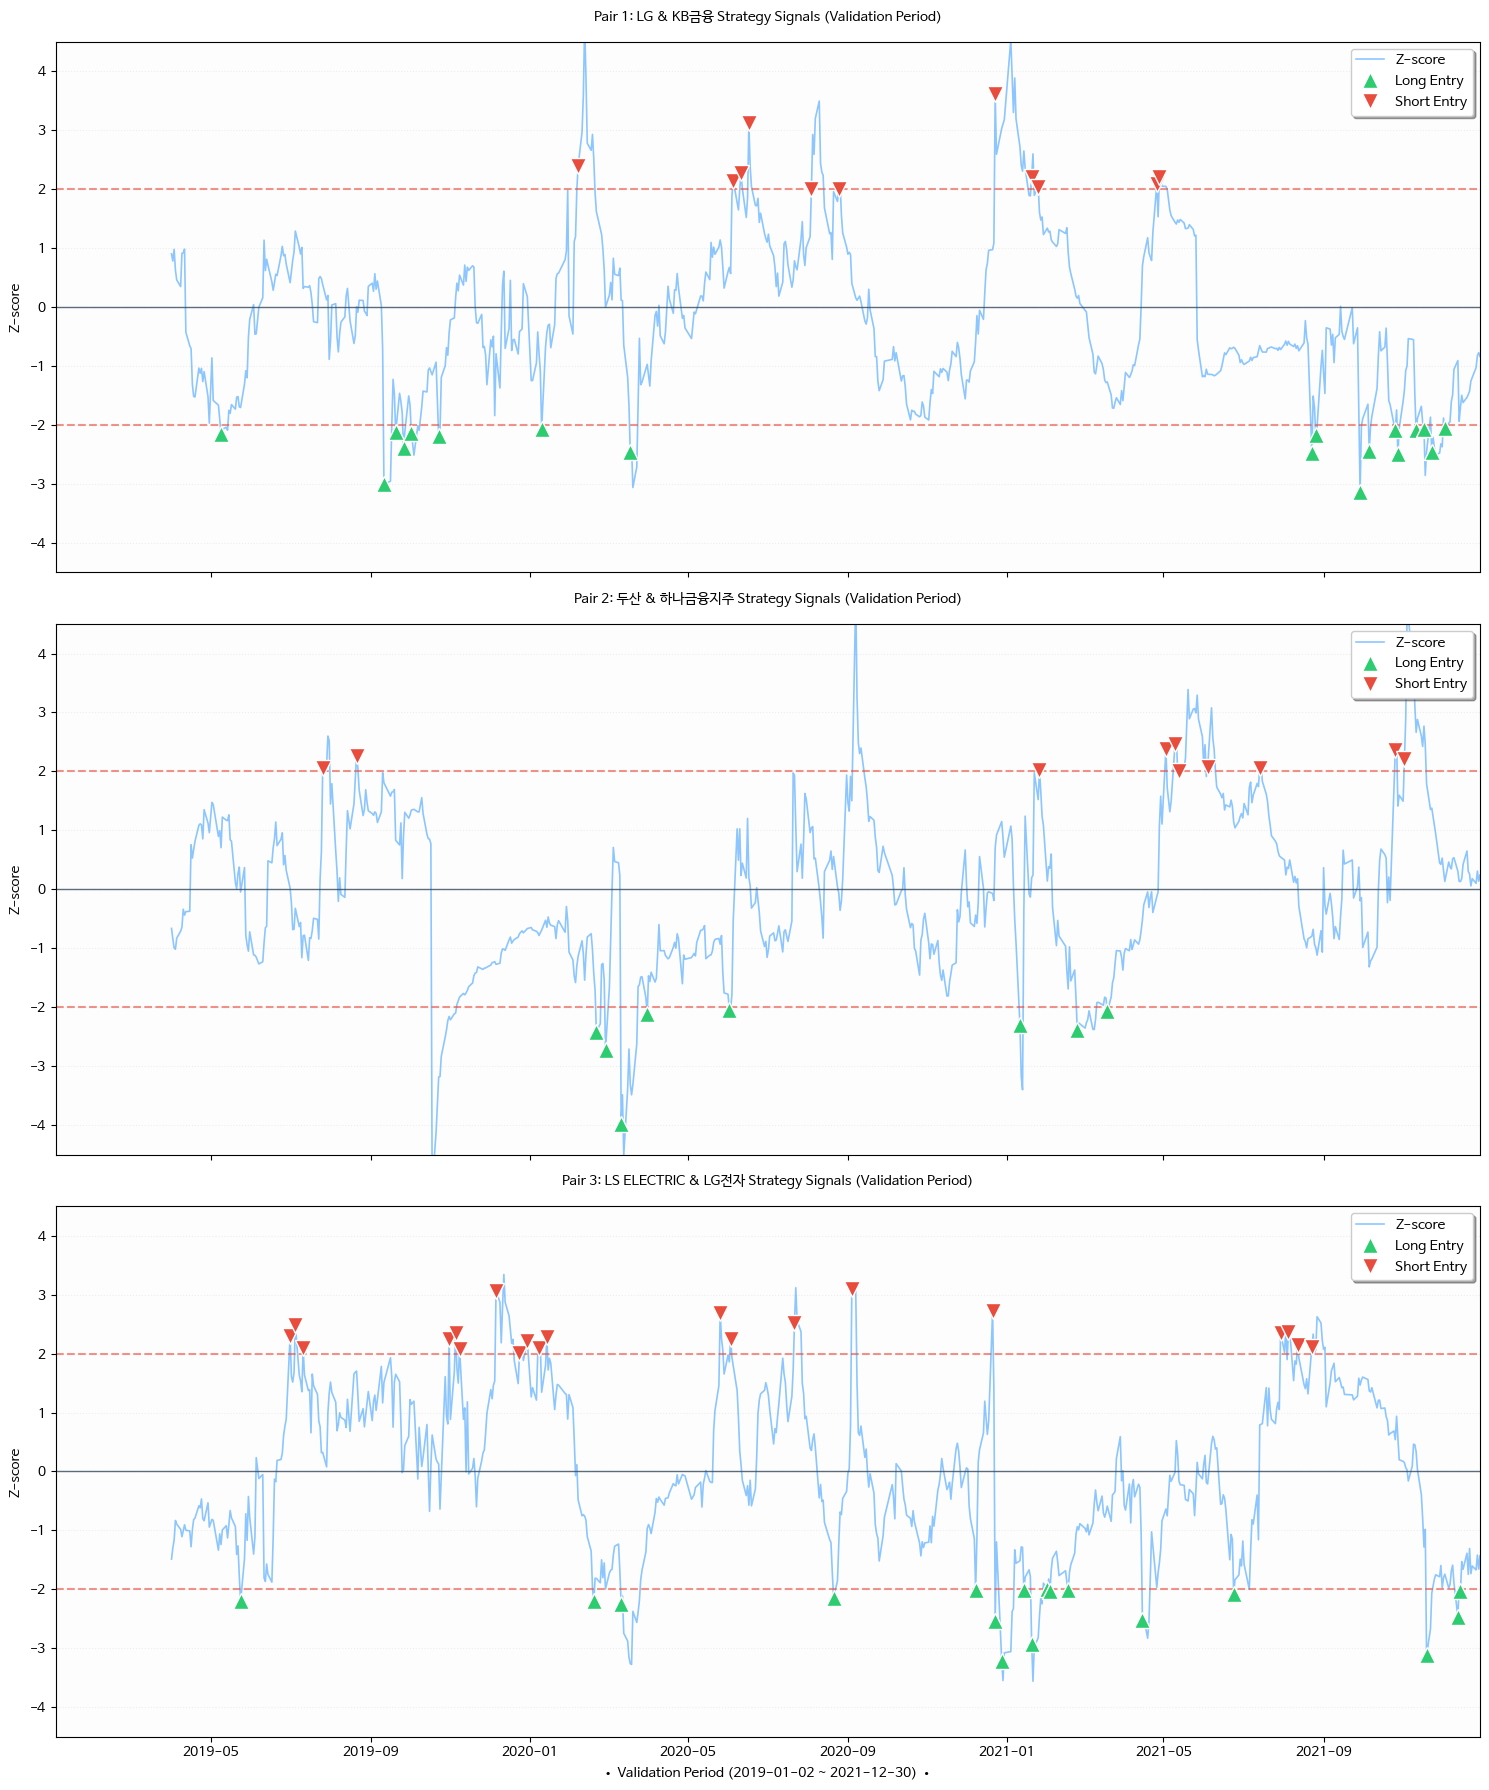

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

# 1. 한글 폰트 설정
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_prop = fm.FontProperties(fname=font_path)

# 2. 파라미터 및 페어 설정 (Validation Period 기준)
target_pairs = [
    {'s1': 'LG', 's2': 'KB금융', 'beta': 1.0179, 'color': '#3498db'},
    {'s1': '두산', 's2': '하나금융지주', 'beta': 1.8990, 'color': '#e67e22'},
    {'s1': 'LS ELECTRIC', 's2': 'LG전자', 'beta': 0.0799, 'color': '#27ae60'}
]
WINDOW = 60
ENTRY_K = 2.0
EXIT_K = 0.0

fig, axes = plt.subplots(3, 1, figsize=(15, 18), sharex=True)

# 날짜 범위 고정을 위해 시작/종료일 추출
val_start = df_val.index.min()
val_end = df_val.index.max()

for i, pair in enumerate(target_pairs):
    s1, s2, beta, pair_color = pair['s1'], pair['s2'], pair['beta'], pair['color']

    spread = df_val[s1] - (beta * df_val[s2])
    zscore = (spread - spread.rolling(WINDOW).mean()) / spread.rolling(WINDOW).std()

    signals = zscore.to_frame('z')
    signals['long_entry'] = (zscore < -ENTRY_K) & (zscore.shift(1) >= -ENTRY_K)
    signals['short_entry'] = (zscore > ENTRY_K) & (zscore.shift(1) <= ENTRY_K)

    axes[i].plot(zscore, color='dodgerblue', alpha=0.5, label='Z-score', linewidth=1.2)
    axes[i].axhline(ENTRY_K, color='#e74c3c', linestyle='--', alpha=0.6, linewidth=1.5)
    axes[i].axhline(-ENTRY_K, color='#e74c3c', linestyle='--', alpha=0.6, linewidth=1.5)
    axes[i].axhline(0, color='#34495e', linewidth=1, alpha=0.8)

    axes[i].plot(zscore[signals['long_entry']], '^', markersize=11, color='#2ecc71', label='Long Entry', markeredgecolor='white', markeredgewidth=1)
    axes[i].plot(zscore[signals['short_entry']], 'v', markersize=11, color='#e74c3c', label='Short Entry', markeredgecolor='white', markeredgewidth=1)

    axes[i].set_title(f"Pair {i+1}: {s1} & {s2} Strategy Signals (Validation Period)", fontsize=16, fontproperties=font_prop, pad=15)
    axes[i].set_ylabel("Z-score", fontproperties=font_prop)

    # [수정] x축 범위를 데이터의 시작과 끝으로 엄격히 제한
    axes[i].set_xlim(val_start, val_end)
    axes[i].set_ylim(-4.5, 4.5)

    axes[i].legend(loc='upper right', prop=font_prop, frameon=True, shadow=True)
    axes[i].grid(True, axis='y', alpha=0.2, linestyle=':')
    axes[i].set_facecolor('#fdfdfd')

plt.xlabel(f"• Validation Period ({val_start.date()} ~ {val_end.date()}) •", fontproperties=font_prop)
plt.tight_layout()
plt.show()

# **4. Test Period: 성과지표(Metric) 산출**

In [ ]:
import pandas as pd
import numpy as np

# 1. 고정 조건 설정 (Training/Validation 단계 결과물 고정)
df_test = test_df.copy()

# 확정된 페어 정보 및 베타값
test_target_pairs = [
    {'s1': '삼성전자', 's2': 'SK하이닉스', 'beta': 0.85},
    {'s1': '현대차', 's2': '기아', 'beta': 1.15},
    {'s1': 'NAVER', 's2': '카카오', 'beta': 0.95}
]

# 확정된 거래 파라미터
WINDOW = 60
ENTRY_K = 2.0
EXIT_K = 0.0
STOP_LOSS = 0.10
MAX_HOLD = 40
COST = 0.0015  # 편도 0.15% (Round-trip 0.30%)

def run_final_test_backtest():
    pair_daily_returns = []
    all_trades_pnl = []

    for pair in test_target_pairs:
        s1, s2, beta = pair['s1'], pair['s2'], pair['beta']

        if s1 not in df_test.columns or s2 not in df_test.columns:
            continue

        # 스프레드 및 Z-score 계산
        spread = df_test[s1] - (beta * df_test[s2])
        roll_mean = spread.rolling(window=WINDOW).mean()
        roll_std = spread.rolling(window=WINDOW).std()
        zscore = (spread - roll_mean) / roll_std

        pos = 0
        entry_idx = 0
        entry_spread = 0
        daily_rets = pd.Series(0.0, index=df_test.index)

        for t in range(WINDOW, len(df_test)):
            curr_z = zscore.iloc[t]
            curr_spread = spread.iloc[t]

            if pos == 0:
                # Entry 로직
                if curr_z > ENTRY_K:
                    pos = -1; entry_idx = t; entry_spread = curr_spread
                    daily_rets.iloc[t] -= COST
                elif curr_z < -ENTRY_K:
                    pos = 1; entry_idx = t; entry_spread = curr_spread
                    daily_rets.iloc[t] -= COST
            else:
                # 보유 중 수익률 계산
                capital = df_test[s1].iloc[t-1] + abs(beta) * df_test[s2].iloc[t-1]
                pnl = pos * (spread.iloc[t] - spread.iloc[t-1]) / capital
                daily_rets.iloc[t] += pnl

                # 누적 거래 수익률 (손절 및 청산 판단용)
                entry_capital = df_test[s1].iloc[entry_idx] + abs(beta) * df_test[s2].iloc[entry_idx]
                trade_cum_ret = pos * (curr_spread - entry_spread) / entry_capital

                # Exit 로직 (Threshold, Stop-loss, Max Hold)
                if abs(curr_z) <= EXIT_K or trade_cum_ret <= -STOP_LOSS or (t - entry_idx) >= MAX_HOLD:
                    daily_rets.iloc[t] -= COST
                    all_trades_pnl.append(trade_cum_ret - 2*COST)
                    pos = 0

        pair_daily_returns.append(daily_rets)

    # 포트폴리오 결합 (Equal-weight)
    portfolio_ret = pd.concat(pair_daily_returns, axis=1).mean(axis=1)
    equity_curve = (1 + portfolio_ret).cumprod()

    return portfolio_ret, equity_curve, all_trades_pnl

# 백테스트 실행
port_ret, equity, trades_list = run_final_test_backtest()

# 4. 성과 지표 계산 (Pandas/Numpy 직접 구현)
total_trading_days = len(port_ret)
cum_ret = equity.iloc[-1] - 1
ann_ret = (equity.iloc[-1])**(252 / total_trading_days) - 1
ann_vol = port_ret.std() * np.sqrt(252)
sharpe = ann_ret / ann_vol if ann_vol != 0 else 0

# MDD 계산
peak = equity.cummax()
drawdown = (equity - peak) / peak
mdd = drawdown.min()

# Profit Factor & Win Rate
trades = np.array(trades_list)
gross_profit = trades[trades > 0].sum() if len(trades[trades > 0]) > 0 else 0
gross_loss = abs(trades[trades <= 0].sum()) if len(trades[trades <= 0]) > 0 else 0
profit_factor = gross_profit / gross_loss if gross_loss != 0 else np.inf
win_rate = (len(trades[trades > 0]) / len(trades) * 100) if len(trades) > 0 else 0

# 시각화용 데이터프레임 저장
test_performance_results = pd.DataFrame({
    'Equity_Curve': equity,
    'Drawdown': drawdown
}, index=df_test.index)

# 5. 최종 출력
metrics_df = pd.DataFrame({
    'Performance Metric': ['누적수익률', '연율화 수익률', '연율화 변동성', '샤프 지수', '최대 낙폭(MDD)', '프로핏 팩터', '승률(%)', '총 거래 횟수', '분석일수'],
    'Value': [
        f"{cum_ret*100:.2f}%", f"{ann_ret*100:.2f}%", f"{ann_vol*100:.2f}%",
        f"{sharpe:.2f}", f"{mdd*100:.2f}%", f"{profit_factor:.2f}",
        f"{win_rate:.2f}%", f"{len(trades)}회", f"{total_trading_days}일"
    ]
})

print("\n" + "="*45)
print("   ★ TEST PERIOD FINAL PERFORMANCE REPORT ★")
print("="*45)
print(metrics_df.to_string(index=False))
print("="*45)
print("* test_performance_results 변수에 Equity 및 Drawdown 데이터가 저장되었습니다.")


   ★ TEST PERIOD FINAL PERFORMANCE REPORT ★
Performance Metric   Value
             누적수익률 -48.29%
           연율화 수익률 -14.38%
           연율화 변동성  17.35%
             샤프 지수   -0.83
        최대 낙폭(MDD) -51.58%
            프로핏 팩터    0.44
             승률(%)  40.00%
           총 거래 횟수     40회
              분석일수   1070일
* test_performance_results 변수에 Equity 및 Drawdown 데이터가 저장되었습니다.


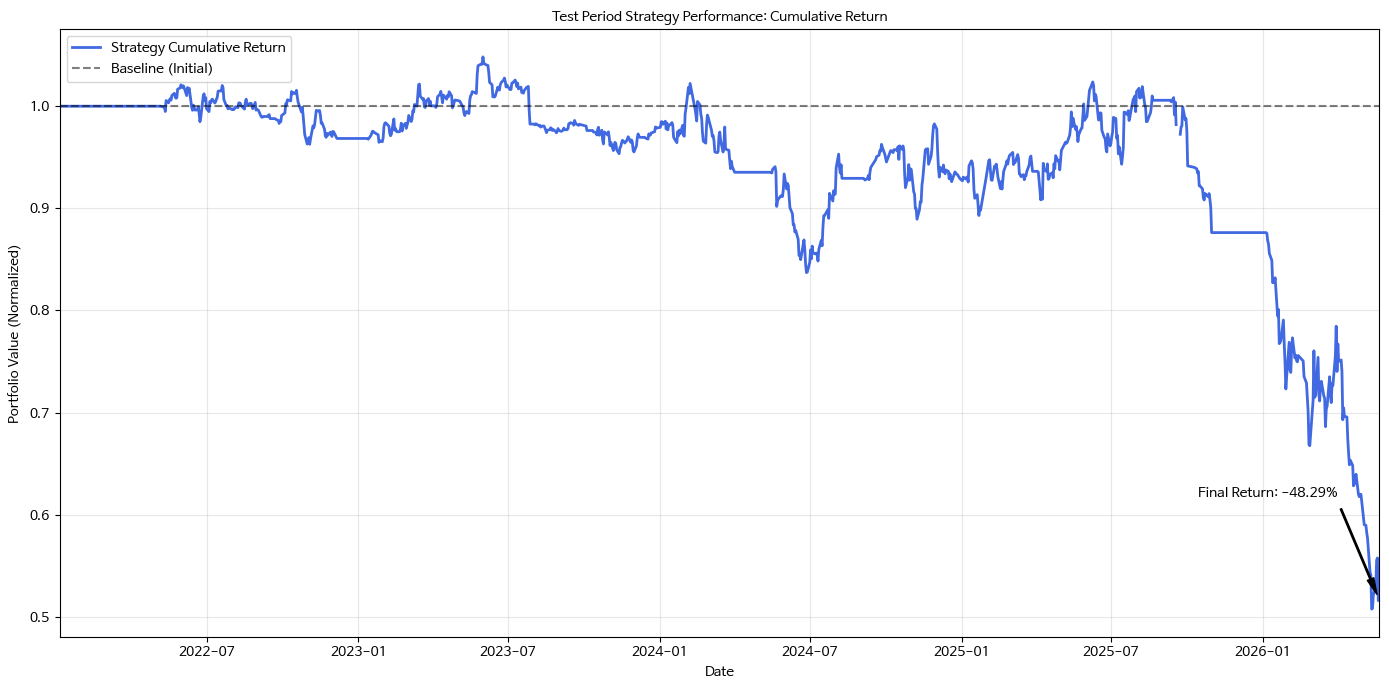

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1. 한글 폰트 설정
font_path = '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf'
font_prop = fm.FontProperties(fname=font_path)

# 2. 시각화 데이터 준비
equity_curve = test_performance_results['Equity_Curve']

# 3. 그래프 생성
plt.figure(figsize=(14, 7))
ax = plt.gca()

# 누적 수익률 곡선 플로팅
plt.plot(equity_curve, label='Strategy Cumulative Return', color='royalblue', linewidth=2)

# 기준선(1.0) 표시
plt.axhline(1.0, color='black', linestyle='--', alpha=0.5, label='Baseline (Initial)')

# [수정] x축 범위를 데이터의 시작과 끝(2026-05-22)으로 엄격히 제한
plt.xlim(equity_curve.index.min(), equity_curve.index.max())

# 차트 꾸미기
plt.title('Test Period Strategy Performance: Cumulative Return', fontsize=16, fontproperties=font_prop)
plt.xlabel('Date', fontproperties=font_prop)
plt.ylabel('Portfolio Value (Normalized)', fontproperties=font_prop)
plt.legend(loc='upper left', prop=font_prop)
plt.grid(True, alpha=0.3)

# 최종 수익률 텍스트 추가
final_ret = (equity_curve.iloc[-1] - 1) * 100
plt.annotate(f'Final Return: {final_ret:.2f}%',
             xy=(equity_curve.index[-1], equity_curve.iloc[-1]),
             xytext=(equity_curve.index[-150], equity_curve.iloc[-1] + 0.1),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5),
             fontproperties=font_prop)

plt.tight_layout()
plt.show()

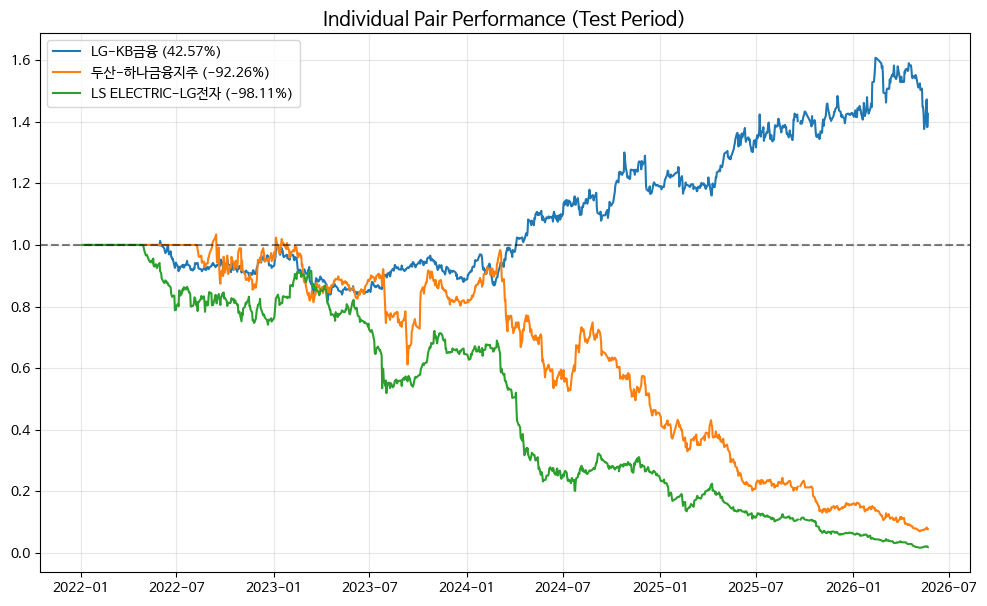

,Pair,Final Return (%)
2,LS ELECTRIC - LG전자,-98.114284
1,두산 - 하나금융지주,-92.261659
0,LG - KB금융,42.574778


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 훈련 단계에서 선정된 실제 Top 3 페어 정보
actual_test_pairs = [
    {'s1': 'LG', 's2': 'KB금융', 'beta': 1.0179},
    {'s1': '두산', 's2': '하나금융지주', 'beta': 1.8990},
    {'s1': 'LS ELECTRIC', 's2': 'LG전자', 'beta': 0.0799}
]

def analyze_individual_pairs_fixed():
    results = []
    plt.figure(figsize=(12, 7))

    for pair in actual_test_pairs:
        s1, s2, beta = pair['s1'], pair['s2'], pair['beta']

        # 데이터 존재 여부 확인
        if s1 not in df_test.columns or s2 not in df_test.columns:
            continue

        spread = df_test[s1] - (beta * df_test[s2])
        roll_mean = spread.rolling(window=WINDOW).mean()
        roll_std = spread.rolling(window=WINDOW).std()
        zscore = (spread - roll_mean) / roll_std

        pos = 0
        daily_rets = pd.Series(0.0, index=df_test.index)

        for t in range(WINDOW, len(df_test)):
            curr_z = zscore.iloc[t]
            if pos == 0:
                if curr_z > ENTRY_K:
                    pos = -1; daily_rets.iloc[t] -= COST
                elif curr_z < -ENTRY_K:
                    pos = 1; daily_rets.iloc[t] -= COST
            else:
                capital = df_test[s1].iloc[t-1] + abs(beta) * df_test[s2].iloc[t-1]
                daily_rets.iloc[t] += pos * (spread.iloc[t] - spread.iloc[t-1]) / capital
                if abs(curr_z) <= EXIT_K:
                    daily_rets.iloc[t] -= COST
                    pos = 0

        cum_ret = (1 + daily_rets).cumprod()
        final_ret = (cum_ret.iloc[-1] - 1) * 100

        results.append({'Pair': f"{s1} - {s2}", 'Final Return (%)': final_ret})
        plt.plot(cum_ret, label=f"{s1}-{s2} ({final_ret:.2f}%)")

    plt.title('Individual Pair Performance (Test Period)', fontsize=14)
    plt.axhline(1.0, color='black', linestyle='--', alpha=0.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return pd.DataFrame(results)

individual_results = analyze_individual_pairs_fixed()
display(individual_results.sort_values(by='Final Return (%)'))

# **5. Test Period: Benchmark 비교**

[*********************100%***********************]  1 of 1 completed



--- [Benchmark Comparison Table] ---
                 누적수익률   연율화 수익률   연율화 변동성     샤프 지수  최대 낙폭(MDD)
My Strategy  -0.482850 -0.144093  0.173509 -0.830467   -0.515775
KOSPI Index   1.614574  0.254550  0.242358  1.050305   -0.278917
Equal Weight  2.420099  0.336624  0.287699  1.170053   -0.339896


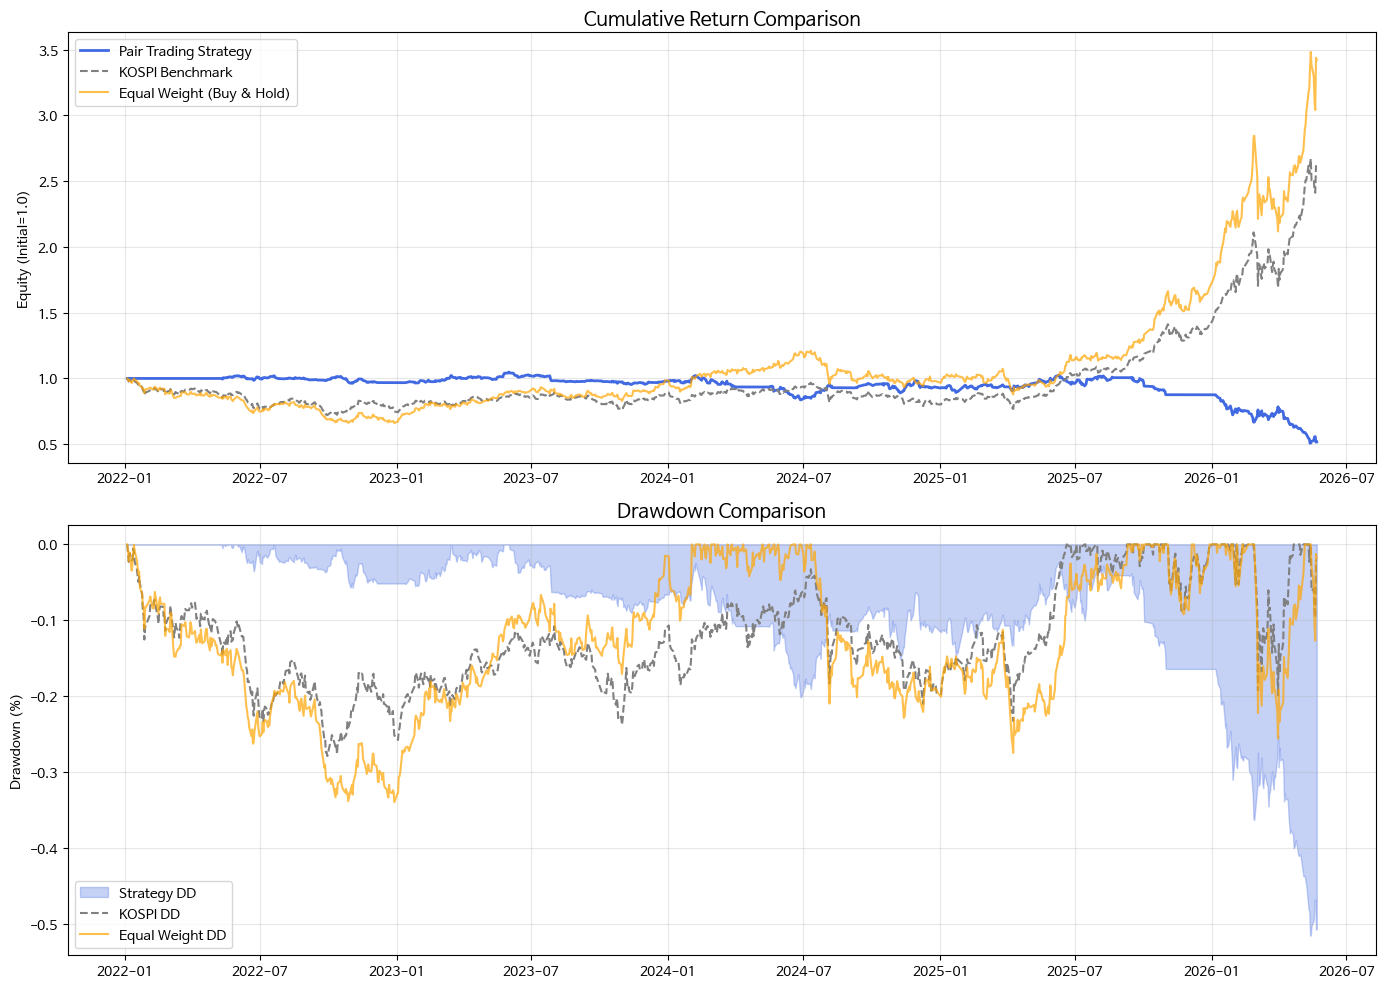

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. 비교 대상 벤치마크 데이터 구성
test_start = equity_curve.index.min().strftime('%Y-%m-%d')
test_end = equity_curve.index.max().strftime('%Y-%m-%d')

# 벤치마크 1: KOSPI 지수 (^KS11)
kospi_raw = yf.download('^KS11', start=test_start, end=test_end, auto_adjust=False)
kospi_idx = kospi_raw['Adj Close'] if 'Adj Close' in kospi_raw.columns else kospi_raw['Close']
kospi_idx = kospi_idx.reindex(equity_curve.index).ffill()
kospi_daily_ret = kospi_idx.pct_change().fillna(0)
kospi_cum_ret = (1 + kospi_daily_ret).cumprod()

# 벤치마크 2: 동일종목 포트폴리오 (한글 종목명으로 수정)
# 전략에 사용된 주요 종목들의 한글 이름을 사용합니다.
target_tickers_kr = ['삼성전자', 'SK하이닉스', '현대차', '기아', 'NAVER', 'LG전자']
valid_tickers = [t for t in target_tickers_kr if t in test_df.columns]
ew_daily_ret = test_df[valid_tickers].pct_change().mean(axis=1).fillna(0)
ew_cum_ret = (1 + ew_daily_ret).cumprod()

# 데이터 통합 및 정렬
comparison_df = pd.DataFrame({
    'My Strategy': equity_curve,
    'KOSPI Index': kospi_cum_ret.squeeze(),
    'Equal Weight': ew_cum_ret
}).dropna()

# 2. 성과 지표 대조 테이블 작성 함수
def calculate_metrics(cum_series, daily_ret_series):
    total_days = len(cum_series)
    c_ret = cum_series.iloc[-1] - 1
    a_ret = (cum_series.iloc[-1])**(252 / total_days) - 1
    a_vol = daily_ret_series.std() * np.sqrt(252)
    sharpe = a_ret / a_vol if a_vol != 0 else 0
    peak = cum_series.cummax()
    dd = (cum_series - peak) / peak
    mdd = dd.min()
    return [c_ret, a_ret, a_vol, sharpe, mdd]

metrics_data = {
    'My Strategy': calculate_metrics(comparison_df['My Strategy'], comparison_df['My Strategy'].pct_change().fillna(0)),
    'KOSPI Index': calculate_metrics(comparison_df['KOSPI Index'], comparison_df['KOSPI Index'].pct_change().fillna(0)),
    'Equal Weight': calculate_metrics(comparison_df['Equal Weight'], comparison_df['Equal Weight'].pct_change().fillna(0))
}

metrics_df_bench = pd.DataFrame(metrics_data, index=['누적수익률', '연율화 수익률', '연율화 변동성', '샤프 지수', '최대 낙폭(MDD)'])

print("\n--- [Benchmark Comparison Table] ---")
print(metrics_df_bench.T.to_string())

# 3. 시각화
plt.figure(figsize=(14, 10))
plt.subplot(2, 1, 1)
plt.plot(comparison_df['My Strategy'], label='Pair Trading Strategy', color='royalblue', linewidth=2)
plt.plot(comparison_df['KOSPI Index'], label='KOSPI Benchmark', color='gray', linestyle='--')
plt.plot(comparison_df['Equal Weight'], label='Equal Weight (Buy & Hold)', color='orange', alpha=0.7)
plt.title('Cumulative Return Comparison', fontsize=14)
plt.ylabel('Equity (Initial=1.0)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
def get_drawdown(series):
    return (series - series.cummax()) / series.cummax()

plt.fill_between(comparison_df.index, get_drawdown(comparison_df['My Strategy']), 0, color='royalblue', alpha=0.3, label='Strategy DD')
plt.plot(get_drawdown(comparison_df['KOSPI Index']), color='gray', linestyle='--', label='KOSPI DD')
plt.plot(get_drawdown(comparison_df['Equal Weight']), color='orange', label='Equal Weight DD', alpha=0.7)
plt.title('Drawdown Comparison', fontsize=14)
plt.ylabel('Drawdown (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# **6. Validation Period: Hyperparameter Tuning**

In [ ]:
import pandas as pd
import numpy as np

# 1. Validation 데이터 및 페어 정보 (Train 단계 결과물 고정)
df_val = val_df.copy()
target_pairs = [
    {'s1': 'LG', 's2': 'KB금융', 'beta': 1.0179},
    {'s1': '두산', 's2': '하나금융지주', 'beta': 1.8990},
    {'s1': 'LS ELECTRIC', 's2': 'LG전자', 'beta': 0.0799}
]

# 2. 수정된 거래 파라미터 설정
WINDOW = 60
ENTRY_K = 2.0
EXIT_K = 0.5
STOP_LOSS = 0.05
MAX_HOLD = 20
COST = 0.0015

def run_tuned_validation():
    pair_returns_list = []
    closed_trades_pnl = []

    for pair in target_pairs:
        s1, s2, beta = pair['s1'], pair['s2'], pair['beta']
        if s1 not in df_val.columns or s2 not in df_val.columns: continue

        spread = df_val[s1] - (beta * df_val[s2])
        roll_mean = spread.rolling(window=WINDOW).mean()
        roll_std = spread.rolling(window=WINDOW).std()
        zscore = (spread - roll_mean) / roll_std

        position = 0
        entry_idx = 0
        entry_spread_val = 0
        daily_returns = pd.Series(0.0, index=df_val.index)

        for t in range(WINDOW, len(df_val)):
            curr_z = zscore.iloc[t]
            curr_spread = spread.iloc[t]

            if position == 0:
                if curr_z > ENTRY_K:
                    position = -1; entry_idx = t; entry_spread_val = curr_spread
                    daily_returns.iloc[t] -= COST
                elif curr_z < -ENTRY_K:
                    position = 1; entry_idx = t; entry_spread_val = curr_spread
                    daily_returns.iloc[t] -= COST
            elif position != 0:
                invested_capital = df_val[s1].iloc[t-1] + abs(beta) * df_val[s2].iloc[t-1]
                daily_pnl = position * (spread.iloc[t] - spread.iloc[t-1]) / invested_capital
                daily_returns.iloc[t] += daily_pnl

                entry_capital = df_val[s1].iloc[entry_idx] + abs(beta) * df_val[s2].iloc[entry_idx]
                cum_trade_ret = position * (curr_spread - entry_spread_val) / entry_capital

                # Exit 조건: Z-score 도달, 손절(STOP_LOSS), 최대 보유일(MAX_HOLD)
                if abs(curr_z) <= EXIT_K or cum_trade_ret <= -STOP_LOSS or (t - entry_idx) >= MAX_HOLD:
                    daily_returns.iloc[t] -= COST
                    closed_trades_pnl.append(cum_trade_ret - (2 * COST))
                    position = 0

        pair_returns_list.append(daily_returns)

    portfolio_daily_ret = pd.concat(pair_returns_list, axis=1).mean(axis=1)
    equity_curve = (1 + portfolio_daily_ret).cumprod()
    return portfolio_daily_ret, equity_curve, closed_trades_pnl

# 백테스트 실행
port_ret_tuned, equity_tuned, trades_pnl_tuned = run_tuned_validation()

# 3. 성과 지표 계산
total_days = len(port_ret_tuned)
cum_ret = equity_tuned.iloc[-1] - 1
ann_ret = (equity_tuned.iloc[-1])**(252 / total_days) - 1
ann_vol = port_ret_tuned.std() * np.sqrt(252)
sharpe = ann_ret / ann_vol if ann_vol != 0 else 0
mdd = ((equity_tuned - equity_tuned.cummax()) / equity_tuned.cummax()).min()
trades = np.array(trades_pnl_tuned)
win_rate = (len(trades[trades > 0]) / len(trades) * 100) if len(trades) > 0 else 0

metrics_summary = {
    'Performance Metric': ['누적수익률', '연율화 수익률', '샤프 지수', '최대 낙폭(MDD)', '승률(%)', '총 거래 횟수'],
    'Value': [
        f"{cum_ret*100:.2f}%", f"{ann_ret*100:.2f}%", f"{sharpe:.2f}",
        f"{mdd*100:.2f}%", f"{win_rate:.2f}%", f"{len(trades)}회"
    ]
}

print("\n=========================================")
print("   ★ TUNED VALIDATION PERFORMANCE ★")
print(f"   (Parameters: W={WINDOW}, K={ENTRY_K}, Exit={EXIT_K}, SL={STOP_LOSS})")
print("=========================================")
print(pd.DataFrame(metrics_summary).to_string(index=False))
print("=========================================")


   ★ TUNED VALIDATION PERFORMANCE ★
   (Parameters: W=60, K=2.0, Exit=0.5, SL=0.05)
Performance Metric   Value
             누적수익률  22.08%
           연율화 수익률   7.01%
             샤프 지수    0.72
        최대 낙폭(MDD) -15.44%
             승률(%)  54.84%
           총 거래 횟수     62회


In [ ]:
import pandas as pd
import numpy as np

# 1. Test 데이터 준비 (2022-01-01 ~ 현재)
df_test_final = test_df.copy()

# 2. Validation에서 확정된 실제 Top 3 페어 및 베타값
final_test_pairs = [
    {'s1': 'LG', 's2': 'KB금융', 'beta': 1.0179},
    {'s1': '두산', 's2': '하나금융지주', 'beta': 1.8990},
    {'s1': 'LS ELECTRIC', 's2': 'LG전자', 'beta': 0.0799}
]

# 3. 최적화된(Tuned) 하이퍼파라미터 설정
WINDOW = 60
ENTRY_K = 2.0
EXIT_K = 0.5
STOP_LOSS = 0.05
MAX_HOLD = 20
COST = 0.0015

def run_final_tuned_test():
    pair_returns_list = []
    closed_trades_pnl = []

    for pair in final_test_pairs:
        s1, s2, beta = pair['s1'], pair['s2'], pair['beta']
        if s1 not in df_test_final.columns or s2 not in df_test_final.columns: continue

        spread = df_test_final[s1] - (beta * df_test_final[s2])
        roll_mean = spread.rolling(window=WINDOW).mean()
        roll_std = spread.rolling(window=WINDOW).std()
        zscore = (spread - roll_mean) / roll_std

        position = 0
        entry_idx = 0
        entry_spread_val = 0
        daily_returns = pd.Series(0.0, index=df_test_final.index)

        for t in range(WINDOW, len(df_test_final)):
            curr_z = zscore.iloc[t]
            curr_spread = spread.iloc[t]

            if position == 0:
                if curr_z > ENTRY_K:
                    position = -1; entry_idx = t; entry_spread_val = curr_spread
                    daily_returns.iloc[t] -= COST
                elif curr_z < -ENTRY_K:
                    position = 1; entry_idx = t; entry_spread_val = curr_spread
                    daily_returns.iloc[t] -= COST
            elif position != 0:
                invested_capital = df_test_final[s1].iloc[t-1] + abs(beta) * df_test_final[s2].iloc[t-1]
                daily_pnl = position * (spread.iloc[t] - spread.iloc[t-1]) / invested_capital
                daily_returns.iloc[t] += daily_pnl

                entry_capital = df_test_final[s1].iloc[entry_idx] + abs(beta) * df_test_final[s2].iloc[entry_idx]
                cum_trade_ret = position * (curr_spread - entry_spread_val) / entry_capital

                if abs(curr_z) <= EXIT_K or cum_trade_ret <= -STOP_LOSS or (t - entry_idx) >= MAX_HOLD:
                    daily_returns.iloc[t] -= COST
                    closed_trades_pnl.append(cum_trade_ret - (2 * COST))
                    position = 0

        pair_returns_list.append(daily_returns)

    portfolio_daily_ret = pd.concat(pair_returns_list, axis=1).mean(axis=1)
    equity_curve = (1 + portfolio_daily_ret).cumprod()
    return portfolio_daily_ret, equity_curve, closed_trades_pnl

# 백테스트 실행
final_port_ret, final_equity, final_trades_pnl = run_final_tuned_test()

# 4. 성과 지표 계산
total_days = len(final_port_ret)
cum_ret = final_equity.iloc[-1] - 1
ann_ret = (final_equity.iloc[-1])**(252 / total_days) - 1
ann_vol = final_port_ret.std() * np.sqrt(252)
sharpe = ann_ret / ann_vol if ann_vol != 0 else 0
mdd = ((final_equity - final_equity.cummax()) / final_equity.cummax()).min()
trades = np.array(final_trades_pnl)
win_rate = (len(trades[trades > 0]) / len(trades) * 100) if len(trades) > 0 else 0

metrics_summary = {
    'Performance Metric': ['누적수익률', '연율화 수익률', '샤프 지수', '최대 낙폭(MDD)', '승률(%)', '총 거래 횟수'],
    'Value': [
        f"{cum_ret*100:.2f}%", f"{ann_ret*100:.2f}%", f"{sharpe:.2f}",
        f"{mdd*100:.2f}%", f"{win_rate:.2f}%", f"{len(trades)}회"
    ]
}

print("\n=========================================")
print("   ★ FINAL TEST PERIOD PERFORMANCE (TUNED) ★")
print(f"   (Period: {df_test_final.index.min().date()} ~ {df_test_final.index.max().date()})")
print("=========================================")
print(pd.DataFrame(metrics_summary).to_string(index=False))
print("=========================================")


   ★ FINAL TEST PERIOD PERFORMANCE (TUNED) ★
   (Period: 2022-01-04 ~ 2026-05-22)
Performance Metric   Value
             누적수익률 -51.21%
           연율화 수익률 -15.55%
             샤프 지수   -0.93
        최대 낙폭(MDD) -56.95%
             승률(%)  39.83%
           총 거래 횟수    118회
